  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)
Using cached mpmath-1.3.0-py3-none-any.whl (536 kB)
  Attempting uninstall: mpmath
    Found existing installation: mpmath 1.3.0
    Uninstalling mpmath-1.3.0:
      Successfully uninstalled mpmath-1.3.0
  Attempting uninstall: sympy
    Found existing installation: sympy 1.14.0
    Uninstalling sympy-1.14.0:
      Successfully uninstalled sympy-1.14.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [sympy]
Локальная директория для видео: /content/videos
Запуск PPO на cuda | GPU: Tesla T4 | VRAM: 14.6 GB
Итерация   5/400 | Steps:    40960 | Speed:  1022 steps/s | Iteration Time:   7.30s | Reward: -1059.0 | Actor Loss:  -0.023 | Critic Loss:  10.447 | Clip Frac: 0.070
Итерация  10/400 | Steps:    81920 | Speed:  1017 steps/s | Iteration Time:   7.57s | Reward: -1007.4 | Actor Loss:  -0.023 | Critic Loss:   9.426 

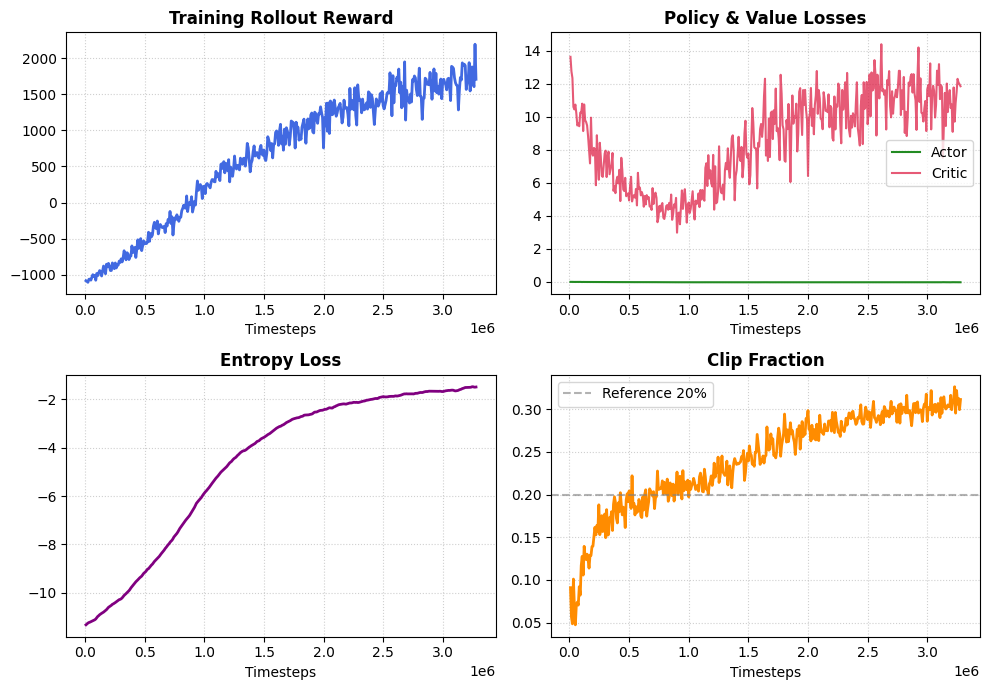


Запуск демонстрации 1: Эвристика...


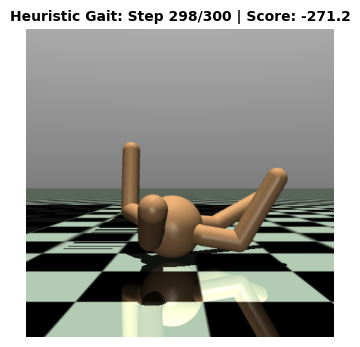

Видео сохранено в сессию: ./videos/ant_heuristic.mp4 (Счёт: -272.4)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Запуск демонстрации 2: Обученный Continuous PPO...


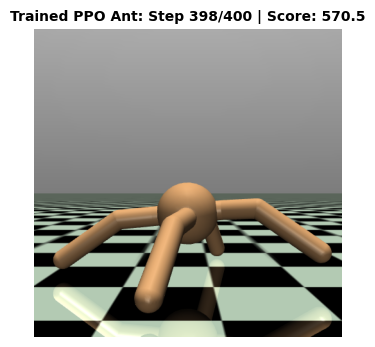

Видео сохранено в сессию: ./videos/ant_ppo_trained.mp4 (Счёт: 571.8)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# =====================================================================
# Установка зависимостей
# =====================================================================
!pip install gymnasium[mujoco]
!pip install --upgrade --force-reinstall sympy

import os
import time
import random
from typing import Tuple

import sympy
import gymnasium as gym
import imageio
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from IPython.display import display
from torch.distributions import Normal
from google.colab import files

os.environ["MUJOCO_GL"] = "egl"

SAVE_DIR = "./videos"
os.makedirs(SAVE_DIR, exist_ok=True)
print(f"Локальная директория для видео: {os.path.abspath(SAVE_DIR)}")

# Ant-v5
#
# Action Space: Box(-1.0, 1.0, (8,), float32) — крутящие моменты (Н·м) в 8 шарнирах ног:
#: hip_4, angle_4 (правая задняя нога)
#: hip_1, angle_1 (левая передняя нога)
#: hip_2, angle_2 (правая передняя нога)
#: hip_3, angle_3 (левая задняя нога)
#
# Observation Space: Box(-inf, inf, (105,), float64) по умолчанию:
#   [0]      : z-координата (высота) торса (м); x, y исключены по умолчанию
#   [1:5]    : ориентация торса в виде кватерниона (w, x, y, z)
#   [5:13]   : углы 8 шарниров ног (рад) в порядке: hip_1, ankle_1, ..., hip_4, ankle_4
#   [13:16]  : линейная скорость торса по осям x, y, z (м/с)
#   [16:19]  : угловая скорость торса по осям x, y, z (рад/с)
#   [19:27]  : угловые скорости 8 шарниров ног (рад/с)
#   [27:105] : внешние контактные силы и моменты cfrc_ext (13 частей тела × 6 значений)

# =====================================================================
# Вспомогательная ортогональная инициализация слоёв
# =====================================================================
def layer_init(layer: nn.Linear, std: float = np.sqrt(2), bias_const: float = 0.0) -> nn.Linear:
    nn.init.orthogonal_(layer.weight, std)
    nn.init.constant_(layer.bias, bias_const)
    return layer


# =====================================================================
# Архитектура Actor-Critic для Ant-v5
# =====================================================================
class ContinuousActorCritic(nn.Module):
    def __init__(self, state_dim: int, action_dim: int, hidden_dim: int = 128):
        super().__init__()
        self.critic = nn.Sequential(
            layer_init(nn.Linear(state_dim, hidden_dim)),
            nn.Tanh(),
            layer_init(nn.Linear(hidden_dim, hidden_dim)),
            nn.Tanh(),
            layer_init(nn.Linear(hidden_dim, 1), std=1.0)
        )

        self.actor_mean = nn.Sequential(
            layer_init(nn.Linear(state_dim, hidden_dim)),
            nn.Tanh(),
            layer_init(nn.Linear(hidden_dim, hidden_dim)),
            nn.Tanh(),
            layer_init(nn.Linear(hidden_dim, action_dim), std=0.01)
        )

        self.actor_logstd = nn.Parameter(torch.zeros(1, action_dim))

    def get_value(self, state: torch.Tensor) -> torch.Tensor:
        return self.critic(state)

    def get_action_and_value(self, state: torch.Tensor, action: torch.Tensor = None):
        action_mean = self.actor_mean(state)
        action_logstd = self.actor_logstd.expand_as(action_mean)
        action_std = torch.exp(action_logstd)

        dist = Normal(action_mean, action_std)

        if action is None:
            action = dist.sample()

        log_prob = dist.log_prob(action).sum(dim=-1)
        entropy = dist.entropy().sum(dim=-1)
        value = self.critic(state).squeeze(-1)

        return action, log_prob, entropy, value


# =====================================================================
# Вычисление Generalized Advantage Estimation (GAE)
# =====================================================================
def compute_gae(
    rewards: torch.Tensor,
    values: torch.Tensor,
    dones: torch.Tensor,
    next_value: torch.Tensor,
    gamma: float = 0.99,
    gae_lambda: float = 0.95
) -> Tuple[torch.Tensor, torch.Tensor]:
    num_steps = rewards.shape[0]
    advantages = torch.zeros_like(rewards)
    last_gae = 0.0

    for t in reversed(range(num_steps)):
        if t == num_steps - 1:
            next_non_terminal = 1.0 - dones[t]
            next_val = next_value
        else:
            next_non_terminal = 1.0 - dones[t + 1]
            next_val = values[t + 1]

        delta = rewards[t] + gamma * next_val * next_non_terminal - values[t]
        last_gae = delta + gamma * gae_lambda * next_non_terminal * last_gae
        advantages[t] = last_gae

    returns = advantages + values
    return advantages, returns


# =====================================================================
# Фабрика окружений
# =====================================================================
def make_env(env_id="Ant-v5", seed=42, render_mode=None):
    def thunk():
        kwargs = {}
        if render_mode is not None:
            kwargs["render_mode"] = render_mode
            kwargs["camera_name"] = "track"

        env = gym.make(env_id, **kwargs)
        env = gym.wrappers.ClipAction(env)
        env = gym.wrappers.NormalizeObservation(env)
        env.action_space.seed(seed)
        return env
    return thunk


# =====================================================================
# Обучающий цикл PPO-Clip
# =====================================================================
def train_ppo_ant(
    env_id="Ant-v5",
    num_envs=8,
    num_steps=1024,
    num_updates=400,
    update_epochs=10,
    num_minibatches=8,
    gamma=0.99,
    gae_lambda=0.95,
    clip_coef=0.2,
    c_val=0.5,
    c_ent=0.005,
    lr=3e-4,
    max_grad_norm=0.5,
    seed=42
):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if torch.cuda.is_available():
        gpu_name = torch.cuda.get_device_name(0)
        gpu_memory = torch.cuda.get_device_properties(0).total_memory / 1024**3

        print(f"Запуск PPO на {device} | GPU: {gpu_name} | VRAM: {gpu_memory:.1f} GB")
    else:
        print(f"Запуск PPO на {device} | GPU не обнаружен")

    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

    envs = gym.vector.SyncVectorEnv([make_env(env_id, seed=seed + i) for i in range(num_envs)])
    state_dim = envs.single_observation_space.shape[0]
    action_dim = envs.single_action_space.shape[0]

    model = ContinuousActorCritic(state_dim, action_dim).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr, eps=1e-5)

    batch_size = num_envs * num_steps
    minibatch_size = batch_size // num_minibatches

    obs_buf = torch.zeros((num_steps, num_envs, state_dim), device=device)
    actions_buf = torch.zeros((num_steps, num_envs, action_dim), device=device)
    logprobs_buf = torch.zeros((num_steps, num_envs), device=device)
    rewards_buf = torch.zeros((num_steps, num_envs), device=device)
    dones_buf = torch.zeros((num_steps, num_envs), device=device)
    values_buf = torch.zeros((num_steps, num_envs), device=device)

    history = {
        "steps": [],
        "rewards": [],
        "actor_loss": [],
        "critic_loss": [],
        "entropy_loss": [],
        "clip_frac": []
    }

    obs, _ = envs.reset(seed=seed)
    next_obs = torch.as_tensor(obs, dtype=torch.float32, device=device)
    next_done = torch.zeros(num_envs, device=device)

    start_time = time.time()

    for update in range(1, num_updates + 1):
        iteration_start = time.time()

        for step in range(num_steps):
            obs_buf[step] = next_obs
            dones_buf[step] = next_done

            with torch.no_grad():
                action, logprob, _, value = model.get_action_and_value(next_obs)
                values_buf[step] = value

            actions_buf[step] = action
            logprobs_buf[step] = logprob

            env_obs, rewards, terms, truncs, _ = envs.step(action.cpu().numpy())
            dones = np.logical_or(terms, truncs)

            rewards_buf[step] = torch.as_tensor(rewards, dtype=torch.float32, device=device)
            next_obs = torch.as_tensor(env_obs, dtype=torch.float32, device=device)
            next_done = torch.as_tensor(dones, dtype=torch.float32, device=device)

        with torch.no_grad():
            next_value = model.get_value(next_obs).squeeze(-1)
            advantages, returns = compute_gae(
                rewards_buf, values_buf, dones_buf, next_value, gamma, gae_lambda
            )

        b_obs = obs_buf.reshape(-1, state_dim)
        b_logprobs = logprobs_buf.reshape(-1)
        b_actions = actions_buf.reshape(-1, action_dim)
        b_advantages = advantages.reshape(-1)
        b_returns = returns.reshape(-1)

        b_inds = np.arange(batch_size)
        epoch_a_loss, epoch_c_loss, epoch_e_loss, epoch_clip = [], [], [], []

        for _ in range(update_epochs):
            np.random.shuffle(b_inds)

            for start in range(0, batch_size, minibatch_size):
                end = start + minibatch_size
                mb_inds = b_inds[start:end]

                _, newlogprob, entropy, newvalue = model.get_action_and_value(
                    b_obs[mb_inds], b_actions[mb_inds]
                )

                logratio = newlogprob - b_logprobs[mb_inds]
                ratio = logratio.exp()

                with torch.no_grad():
                    clip_frac = ((ratio - 1.0).abs() > clip_coef).float().mean().item()
                    epoch_clip.append(clip_frac)

                mb_adv = b_advantages[mb_inds]
                mb_adv = (mb_adv - mb_adv.mean()) / (mb_adv.std() + 1e-8)

                surr1 = -mb_adv * ratio
                surr2 = -mb_adv * torch.clamp(ratio, 1.0 - clip_coef, 1.0 + clip_coef)
                actor_loss = torch.max(surr1, surr2).mean()

                critic_loss = F.smooth_l1_loss(newvalue, b_returns[mb_inds])
                entropy_loss = -entropy.mean()

                total_loss = actor_loss + c_val * critic_loss + c_ent * entropy_loss

                optimizer.zero_grad()
                total_loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
                optimizer.step()

                epoch_a_loss.append(actor_loss.item())
                epoch_c_loss.append(critic_loss.item())
                epoch_e_loss.append(entropy_loss.item())

        current_step = update * batch_size
        iteration_time = time.time() - iteration_start
        elapsed_time = time.time() - start_time
        sps = int(current_step / elapsed_time)

        mean_reward = rewards_buf.sum(dim=0).mean().item()

        history["steps"].append(current_step)
        history["rewards"].append(mean_reward)
        history["actor_loss"].append(float(np.mean(epoch_a_loss)))
        history["critic_loss"].append(float(np.mean(epoch_c_loss)))
        history["entropy_loss"].append(float(np.mean(epoch_e_loss)))
        history["clip_frac"].append(float(np.mean(epoch_clip)))

        if update % 5 == 0:
            print(
                f"Итерация {update:3d}/{num_updates:3d} | "
                f"Steps: {current_step:8d} | "
                f"Speed: {sps:5d} steps/s | "
                f"Iteration Time: {iteration_time:6.2f}s | "
                f"Reward: {mean_reward:7.1f} | "
                f"Actor Loss: {history['actor_loss'][-1]:7.3f} | "
                f"Critic Loss: {history['critic_loss'][-1]:7.3f} | "
                f"Clip Frac: {history['clip_frac'][-1]:.3f}"
            )

    envs.close()
    return model, history


# =====================================================================
# Визуализация метрик
# =====================================================================
def plot_training_metrics(history: dict):
    fig, axes = plt.subplots(2, 2, figsize=(10, 7))

    axes[0, 0].plot(history["steps"], history["rewards"], color='royalblue', linewidth=2)
    axes[0, 0].set_title('Training Rollout Reward', fontweight='bold')
    axes[0, 0].set_xlabel('Timesteps')
    axes[0, 0].grid(True, linestyle=':', alpha=0.6)

    axes[0, 1].plot(history["steps"], history["actor_loss"], color='forestgreen', label='Actor')
    axes[0, 1].plot(history["steps"], history["critic_loss"], color='crimson', alpha=0.7, label='Critic')
    axes[0, 1].set_title('Policy & Value Losses', fontweight='bold')
    axes[0, 1].set_xlabel('Timesteps')
    axes[0, 1].grid(True, linestyle=':', alpha=0.6)
    axes[0, 1].legend()

    axes[1, 0].plot(history["steps"], history["entropy_loss"], color='purple', linewidth=2)
    axes[1, 0].set_title('Entropy Loss', fontweight='bold')
    axes[1, 0].set_xlabel('Timesteps')
    axes[1, 0].grid(True, linestyle=':', alpha=0.6)

    axes[1, 1].plot(history["steps"], history["clip_frac"], color='darkorange', linewidth=2)
    axes[1, 1].axhline(0.2, color='gray', linestyle='--', alpha=0.6, label='Reference 20%')
    axes[1, 1].set_title('Clip Fraction', fontweight='bold')
    axes[1, 1].set_xlabel('Timesteps')
    axes[1, 1].grid(True, linestyle=':', alpha=0.6)
    axes[1, 1].legend()

    plt.tight_layout()
    plt.show()


trained_ant, ant_history = train_ppo_ant()
plot_training_metrics(ant_history)


# =====================================================================
# Демонстрация 1: Эвристическая синусоидальная походка
# =====================================================================
print("\nЗапуск демонстрации 1: Эвристика")

heuristic_env = gym.make(
    "Ant-v5",
    render_mode="rgb_array",
    camera_name="track",
    terminate_when_unhealthy=False
)
_, _ = heuristic_env.reset(seed=42)

frames_heuristic = []
heuristic_return = 0.0
omega = 0.2
TOTAL_STEPS = 300

fig, ax = plt.subplots(figsize=(5, 4))
img = ax.imshow(heuristic_env.render())
ax.set_axis_off()
title_text = ax.set_title("Heuristic: Step 0 | Score: 0.0", fontsize=10, fontweight="bold")
display_handle = display(fig, display_id=True)

for step in range(TOTAL_STEPS):
    t = step * omega
    action = np.array([
         np.sin(t),        np.cos(t),
        -np.sin(t),       -np.cos(t),
         np.sin(t + np.pi), np.cos(t + np.pi),
        -np.sin(t + np.pi),-np.cos(t + np.pi)
    ], dtype=np.float32)

    _, reward, term, trunc, _ = heuristic_env.step(action)
    heuristic_return += reward

    frame = heuristic_env.render()
    frames_heuristic.append(frame)

    if step % 2 == 0:
        img.set_data(frame)
        title_text.set_text(f"Heuristic Gait: Step {step}/{TOTAL_STEPS} | Score: {heuristic_return:,.1f}")
        display_handle.update(fig)

    if term or trunc:
        break

plt.close(fig)
heuristic_env.close()

heuristic_video_path = os.path.join(SAVE_DIR, "ant_heuristic.mp4")
imageio.mimsave(heuristic_video_path, frames_heuristic, fps=30)
print(f"Видео сохранено в сессию: {heuristic_video_path} (Счёт: {heuristic_return:.1f})")
files.download(heuristic_video_path)


# =====================================================================
# Демонстрация 2: Обученный Continuous PPO
# =====================================================================
print("\nЗапуск демонстрации 2: Обученный Continuous PPO")

demo_env = make_env("Ant-v5", seed=123, render_mode="rgb_array")()
demo_env.training = False

state, _ = demo_env.reset(seed=123)
device = next(trained_ant.parameters()).device
trained_ant.eval()

frames_ppo = []
episode_reward = 0.0
TOTAL_STEPS = 400

fig, ax = plt.subplots(figsize=(5, 4))
img = ax.imshow(demo_env.render())
ax.set_axis_off()
title_text = ax.set_title("Trained PPO: Step 0 | Score: 0.0", fontsize=10, fontweight="bold")
display_handle = display(fig, display_id=True)

with torch.no_grad():
    for step in range(TOTAL_STEPS):
        state_tensor = torch.as_tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
        action = trained_ant.actor_mean(state_tensor).squeeze(0).cpu().numpy()

        state, reward, term, trunc, _ = demo_env.step(action)
        episode_reward += reward

        frame = demo_env.render()
        frames_ppo.append(frame)

        if step % 2 == 0:
            img.set_data(frame)
            title_text.set_text(f"Trained PPO Ant: Step {step}/{TOTAL_STEPS} | Score: {episode_reward:,.1f}")
            display_handle.update(fig)

        if term or trunc:
            break

plt.close(fig)
demo_env.close()

ppo_video_path = os.path.join(SAVE_DIR, "ant_ppo_trained.mp4")
imageio.mimsave(ppo_video_path, frames_ppo, fps=30)
print(f"Видео сохранено в сессию: {ppo_video_path} (Счёт: {episode_reward:.1f})")
files.download(ppo_video_path)